# Data Science Salaries: What Pays and Where?

**Questions:** how do experience, job title, company size and remote work affect data-science pay, and how does
Indonesia compare? Rebuilt from my Digital Skola *Wrangler Project* (data wrangling with pandas).

**Data:** 3,755 salary records from 2020–2023, in USD (`data/ds_salaries.csv`, public dataset).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/ds_salaries.csv")
LEVEL = {"EN": "Entry", "MI": "Mid", "SE": "Senior", "EX": "Executive"}
SIZE = {"S": "Small", "M": "Medium", "L": "Large"}
REMOTE = {0: "On-site", 50: "Hybrid", 100: "Fully remote"}
df["level"] = df["experience_level"].map(LEVEL)
df["company"] = df["company_size"].map(SIZE)
df["work_mode"] = df["remote_ratio"].map(REMOTE)
print(df.shape, "| missing:", df.isna().sum().sum(), "| duplicate rows:", df.duplicated().sum())
df["work_year"].value_counts().sort_index()

(3755, 14) | missing: 0 | duplicate rows: 1171


,count
work_year,
2020,76
2021,230
2022,1664
2023,1785


Exact duplicate rows are kept: in salary surveys, two people with the same title and pay are plausible.
Most records come from 2022–2023, so yearly trends are compared with that in mind.

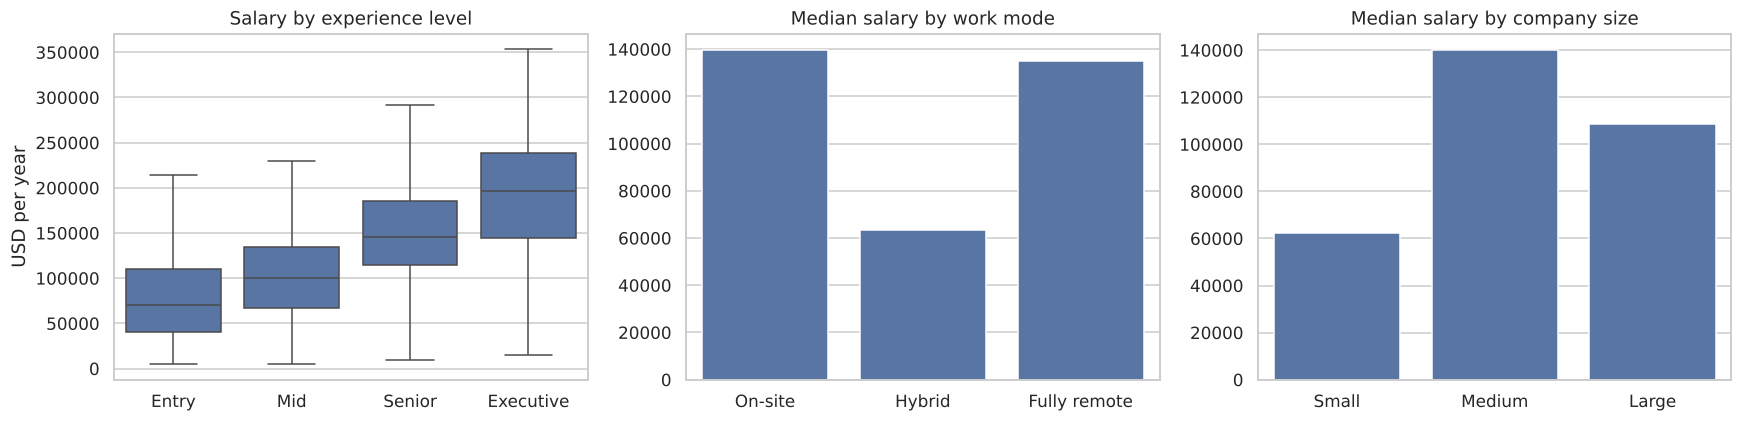

median_usd
by level        Entry            70000.0
                Mid             100000.0
                Senior          146000.0
                Executive       196000.0
by work mode    Fully remote    135000.0
                Hybrid           63312.0
                On-site         139600.0
by company size Large           108500.0
                Medium          140000.0
                Small            62146.0

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = ["Entry", "Mid", "Senior", "Executive"]
sns.boxplot(data=df, x="level", y="salary_in_usd", order=order, ax=axes[0], showfliers=False, color="#4C72B0")
axes[0].set(title="Salary by experience level", xlabel="", ylabel="USD per year")
sns.barplot(data=df, x="work_mode", y="salary_in_usd", estimator=np.median, errorbar=None,
            order=["On-site", "Hybrid", "Fully remote"], ax=axes[1], color="#4C72B0")
axes[1].set(title="Median salary by work mode", xlabel="", ylabel="")
sns.barplot(data=df, x="company", y="salary_in_usd", estimator=np.median, errorbar=None,
            order=["Small", "Medium", "Large"], ax=axes[2], color="#4C72B0")
axes[2].set(title="Median salary by company size", xlabel="", ylabel="")
plt.tight_layout()
summary = pd.concat({
    "by level": df.groupby("level")["salary_in_usd"].median().reindex(order),
    "by work mode": df.groupby("work_mode")["salary_in_usd"].median(),
    "by company size": df.groupby("company")["salary_in_usd"].median(),
})
summary.rename("median_usd").to_frame()

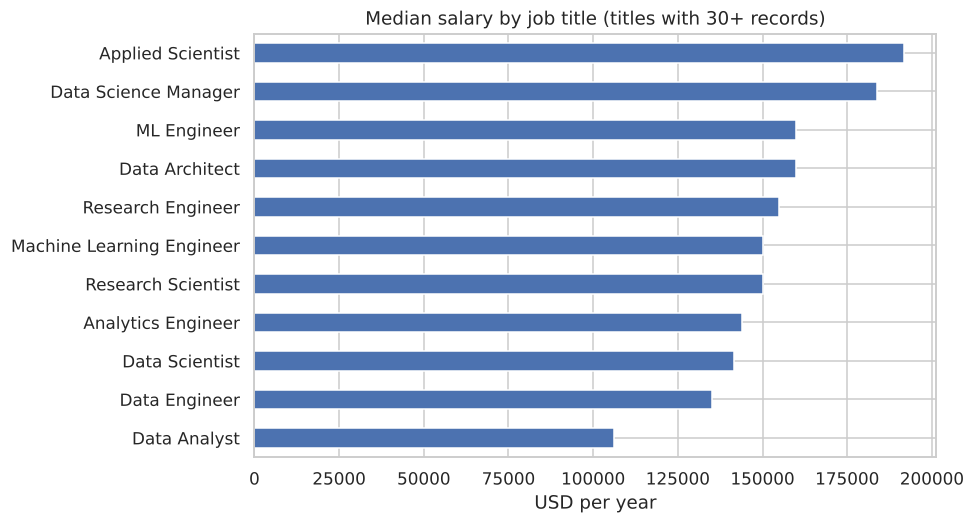

,count,median
job_title,,
Applied Scientist,58,191737.5
Data Science Manager,58,183780.0
Data Architect,101,160000.0
ML Engineer,34,160000.0
Research Engineer,37,155000.0
Machine Learning Engineer,289,150000.0
Research Scientist,82,150000.0
Analytics Engineer,103,143860.0
Data Scientist,840,141525.0


In [4]:
roles = (df.groupby("job_title")["salary_in_usd"].agg(["count", "median"])
           .query("count >= 30").sort_values("median", ascending=False))
ax = roles["median"].sort_values().plot(kind="barh", figsize=(8, 5), color="#4C72B0")
ax.set(title="Median salary by job title (titles with 30+ records)", xlabel="USD per year", ylabel="")
roles

In [5]:
fully_remote_share = (df.groupby("work_year")["remote_ratio"].apply(lambda s: (s == 100).mean()) * 100).round(1)
median_by_year = df.groupby("work_year")["salary_in_usd"].median()
print("Share of fully remote roles by year (%):")
print(fully_remote_share.to_string())
print("\nMedian salary by year (USD):")
print(median_by_year.to_string())

Share of fully remote roles by year (%):
work_year
2020    51.3
2021    52.2
2022    53.5
2023    33.2

Median salary by year (USD):
work_year
2020     73065.0
2021     80000.0
2022    131300.0
2023    143860.0


In [6]:
idn = df[df["company_location"] == "ID"]
asia = ["ID", "IN", "SG", "MY", "PH", "TH", "VN", "JP"]
asia_med = (df[df["company_location"].isin(asia)].groupby("company_location")["salary_in_usd"]
              .agg(["count", "median"]).sort_values("median", ascending=False))
print(f"Indonesia-based companies: {len(idn)} records, median USD {idn['salary_in_usd'].median():,.0f}")
remote_from_id = df[(df["employee_residence"] == "ID")]
print(f"Employees living in Indonesia: {len(remote_from_id)} records")
asia_med

Indonesia-based companies: 2 records, median USD 34,208
Employees living in Indonesia: 1 records


,count,median
company_location,,
JP,6,75682.0
SG,6,66113.5
PH,1,50000.0
MY,1,40000.0
ID,2,34208.0
TH,3,24740.0
IN,58,18276.0
VN,1,12000.0


**Findings**

* **Experience is the biggest pay lever.** The median roughly doubles from entry level to senior.
* **Fully remote roles pay about the same as on-site roles at the median** (USD 135k vs 140k), while hybrid roles pay less, so remote work does not mean a lower salary.
* **The share of fully remote roles fell from about 53% in 2022 to 33% in 2023**, so remote jobs are more competitive and a strong portfolio matters more.
* **Medium-sized companies pay the highest median** in this sample. These are mostly US tech firms.
* **Indonesia has very few records**, so the local median is only indicative. Asian markets in this sample pay far below US and European companies, which is why remote roles with foreign employers are attractive.
* *Caveat:* the data is self-reported and dominated by US companies, so treat country comparisons as directional.